In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate our research project
project_root = Path.home() / "Documents" / "air-quality-retrieval-ai"

sys.path.insert(0, str(project_root))

from src.data_loader import load_air_quality_data

# Our loader uses a relative data directory
import os
os.chdir(project_root)

df = load_air_quality_data()

print("Dataset shape:", df.shape)
display(df.head())

Found 12 CSV files
Loading PRSA_Data_Aotizhongxin_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Changping_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Dingling_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Dongsi_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Guanyuan_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Gucheng_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Huairou_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Nongzhanguan_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Shunyi_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Tiantan_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Wanliu_20130301-20170228.csv: 35064 rows
Loading PRSA_Data_Wanshouxigong_20130301-20170228.csv: 35064 rows
Dataset shape: (420768, 19)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


In [2]:
# Define chronological boundaries
train_end = "2015-03-01"
val_end = "2016-03-01"

train_df = df[df["datetime"] < train_end].copy()

val_df = df[
    (df["datetime"] >= train_end)
    & (df["datetime"] < val_end)
].copy()

test_df = df[df["datetime"] >= val_end].copy()

# Validate the split
assert len(train_df) + len(val_df) + len(test_df) == len(df)

assert train_df["datetime"].max() < val_df["datetime"].min()
assert val_df["datetime"].max() < test_df["datetime"].min()

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Testing rows:", len(test_df))

Training rows: 210240
Validation rows: 105408
Testing rows: 105120


In [3]:
from src.windows import make_windows

HISTORY = 24

# Training windows
X_train, y_train, stations_train, times_train = (
    make_windows(train_df, history=HISTORY)
)

# Validation windows
X_val, y_val, stations_val, times_val = (
    make_windows(val_df, history=HISTORY)
)

# Test windows
X_test, y_test, stations_test, times_test = (
    make_windows(test_df, history=HISTORY)
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (186115, 24) (186115,)
Validation: (87373, 24) (87373,)
Testing: (86977, 24) (86977,)


In [4]:
print("Station:", stations_train[0])
print("Target time:", times_train[0])

print("\nHistorical PM2.5 values:")
print(X_train[0])

print("\nNext-hour PM2.5 target:")
print(y_train[0])

print("\nNumber of historical hours:")
print(len(X_train[0]))

Station: Aotizhongxin
Target time: 2013-03-02T00:00:00.000000000

Historical PM2.5 values:
[ 4.  8.  7.  6.  3.  5.  3.  3.  3.  3.  3.  3.  3.  3.  6.  8.  9. 10.
 11.  8. 11. 12. 15. 24.]

Next-hour PM2.5 target:
22.0

Number of historical hours:
24


In [5]:
import numpy as np

# Correct feature dimensions
assert X_train.shape[1] == 24
assert X_val.shape[1] == 24
assert X_test.shape[1] == 24

# Inputs and targets have matching sample counts
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

# No missing or infinite values
assert np.isfinite(X_train).all()
assert np.isfinite(y_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(y_val).all()
assert np.isfinite(X_test).all()
assert np.isfinite(y_test).all()

# Target timestamps stay inside their splits
assert (times_train < np.datetime64("2015-03-01")).all()

assert (
    (times_val >= np.datetime64("2015-03-01"))
    & (times_val < np.datetime64("2016-03-01"))
).all()

assert (times_test >= np.datetime64("2016-03-01")).all()

print("All window validation checks passed!")

All window validation checks passed!


In [6]:
total_windows = (
    len(X_train) + len(X_val) + len(X_test)
)

print(f"Original observations: {len(df):,}")
print(f"Valid forecasting windows: {total_windows:,}")

for name, original, X in [
    ("Training", train_df, X_train),
    ("Validation", val_df, X_val),
    ("Testing", test_df, X_test),
]:
    print(
        f"{name}: {len(X):,} windows "
        f"from {len(original):,} observations"
    )

Original observations: 420,768
Valid forecasting windows: 360,465
Training: 186,115 windows from 210,240 observations
Validation: 87,373 windows from 105,408 observations
Testing: 86,977 windows from 105,120 observations


In [7]:
import numpy as np

# Persistence: predict the last observed value
y_pred_train = X_train[:, -1]
y_pred_val = X_val[:, -1]
y_pred_test = X_test[:, -1]

print("First five predictions:")
print(y_pred_test[:5])

print("\nFirst five actual values:")
print(y_test[:5])

First five predictions:
[187. 174. 205. 206. 204.]

First five actual values:
[174. 205. 206. 204. 213.]


In [8]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

def evaluate_forecast(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    return {
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3)
    }


print("Training:")
print(evaluate_forecast(y_train, y_pred_train))

print("\nValidation:")
print(evaluate_forecast(y_val, y_pred_val))

print("\nTesting:")
print(evaluate_forecast(y_test, y_pred_test))

Training:
{'MAE': 11.052, 'RMSE': np.float64(20.498)}

Validation:
{'MAE': 9.785, 'RMSE': np.float64(19.059)}

Testing:
{'MAE': 10.136, 'RMSE': np.float64(19.514)}


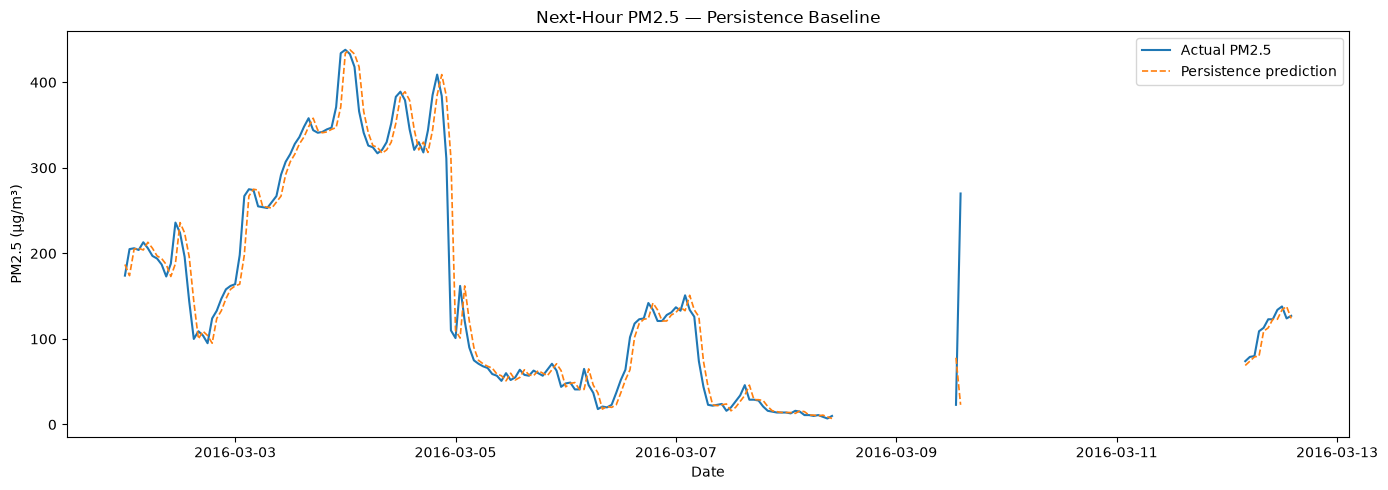

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

station_name = "Aotizhongxin"

mask = stations_test == station_name

plot_df = pd.DataFrame({
    "datetime": pd.to_datetime(times_test[mask]),
    "actual": y_test[mask],
    "predicted": y_pred_test[mask]
})

# Take the first 168 valid prediction samples
plot_df = (
    plot_df.sort_values("datetime")
    .head(168)
    .set_index("datetime")
)

# Reindex to the complete hourly timeline.
# Missing timestamps become NaN, creating line breaks.
hourly_index = pd.date_range(
    start=plot_df.index.min(),
    end=plot_df.index.max(),
    freq="h"
)

plot_df = plot_df.reindex(hourly_index)

plt.figure(figsize=(14, 5))

plt.plot(
    plot_df.index,
    plot_df["actual"],
    label="Actual PM2.5",
    linewidth=1.5
)

plt.plot(
    plot_df.index,
    plot_df["predicted"],
    label="Persistence prediction",
    linestyle="--",
    linewidth=1.2
)

plt.title("Next-Hour PM2.5 — Persistence Baseline")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
import pandas as pd

station_results = []

for station in np.unique(stations_test):

    mask = stations_test == station

    metrics = evaluate_forecast(
        y_test[mask],
        y_pred_test[mask]
    )

    station_results.append({
        "station": station,
        "samples": mask.sum(),
        **metrics
    })

station_results = pd.DataFrame(station_results)

display(
    station_results.sort_values(
        "MAE",
        ascending=False
    )
)

,station,samples,MAE,RMSE
11,Wanshouxigong,7361,11.298,22.873
3,Dongsi,6838,11.070,21.399
8,Shunyi,6593,10.856,20.792
4,Guanyuan,7371,10.605,18.902
9,Tiantan,7499,10.555,18.815
0,Aotizhongxin,7358,10.464,19.642
7,Nongzhanguan,7314,10.283,19.199
5,Gucheng,7284,10.160,20.144
10,Wanliu,7562,9.778,18.584
1,Changping,7313,9.657,18.062


In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def evaluate_forecast(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    return {
        "MAE": round(float(mae), 3),
        "RMSE": round(float(rmse), 3)
    }

### Experiment 1 — Persistence Forecasting Baseline

**Objective:** Establish a simple benchmark for one-hour-ahead PM2.5 forecasting using the most recent observed concentration.

**Method:** A persistence forecast predicts that the next hourly PM2.5 concentration will equal the final value in a 24-hour historical input window.

**Dataset:** Twelve Beijing air-quality monitoring stations, with chronological training, validation, and testing partitions. Only windows containing consecutive hourly timestamps and finite PM2.5 observations were evaluated.

**Results:**

| Dataset | MAE (µg/m³) | RMSE (µg/m³) |
|---|---:|---:|
| Training | 11.052 | 20.498 |
| Validation | 9.785 | 19.059 |
| Testing | 10.136 | 19.514 |

Station-level test MAE ranges from 8.475 µg/m³ at Dingling to 11.298 µg/m³ at Wanshouxigong.

**Interpretation:** Persistence provides a useful benchmark for next-hour forecasting. The difference between MAE and RMSE indicates that relatively large forecast errors contribute substantially to squared-error loss.

**Limitations:** Persistence cannot anticipate abrupt changes in concentration. The evaluation excludes windows containing missing PM2.5 values, and results may not represent performance during sensor outages. More complex methods must be compared using consistent evaluation samples.

**Next experiment:** Train a regression model using the previous 24 hours of PM2.5 measurements and compare its validation performance with persistence.

In [12]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=10.0)

ridge_model.fit(X_train, y_train)

# Generate validation predictions
ridge_val_pred = ridge_model.predict(X_val)

print("Ridge Regression — Validation")
print(evaluate_forecast(y_val, ridge_val_pred))

print("\nPersistence — Validation")
print(evaluate_forecast(y_val, y_pred_val))

Ridge Regression — Validation
{'MAE': 9.677, 'RMSE': 18.274}

Persistence — Validation
{'MAE': 9.785, 'RMSE': 19.059}


In [13]:
comparison = pd.DataFrame([
    {
        "Model": "Persistence",
        **evaluate_forecast(y_val, y_pred_val)
    },
    {
        "Model": "Ridge Regression",
        **evaluate_forecast(y_val, ridge_val_pred)
    }
])

display(comparison)

,Model,MAE,RMSE
0,Persistence,9.785,19.059
1,Ridge Regression,9.677,18.274


### Persistence Forecast Visualization — Interpretation

The persistence forecasting model generally follows gradual changes in hourly PM2.5 concentrations but exhibits a one-hour lag during rapid concentration increases and decreases.

The visualization was adjusted to preserve missing timestamps using hourly reindexing, preventing misleading lines from connecting observations across data gaps.

Sharp concentration changes appear to be important sources of forecasting error.

**Research implication:** More advanced forecasting methods should be evaluated on their ability to predict rapid concentration changes rather than only matching stable pollution periods.

In [14]:
from sklearn.linear_model import Ridge

# Train on historical data only
ridge_model = Ridge(alpha=10.0)

ridge_model.fit(X_train, y_train)

# Predict validation targets
ridge_val_pred = ridge_model.predict(X_val)

print("Ridge Regression:")
print(evaluate_forecast(y_val, ridge_val_pred))

print("\nPersistence:")
print(evaluate_forecast(y_val, y_pred_val))

Ridge Regression:
{'MAE': 9.677, 'RMSE': 18.274}

Persistence:
{'MAE': 9.785, 'RMSE': 19.059}
